# Data Exploration

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hurst as hurst
from statsmodels.tsa.stattools import adfuller

### 


In [4]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_41073/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


In [5]:
df["VZ UN"]


Date
2010-07-30    13.66
2010-08-02    13.90
2010-08-03    13.89
2010-08-04    13.82
2010-08-05    13.89
              ...  
2025-07-23    42.84
2025-07-24    43.08
2025-07-25    43.08
2025-07-28    42.36
2025-07-29    42.71
Name: VZ UN, Length: 3773, dtype: float64

<Axes: xlabel='Date'>

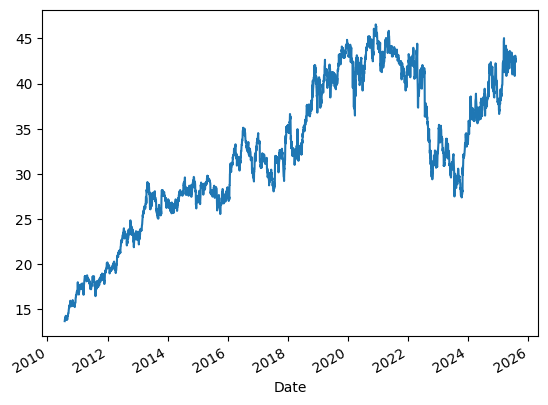

In [6]:
vz_us = df["VZ UN"]
vz_us.plot()

<Axes: xlabel='Date'>

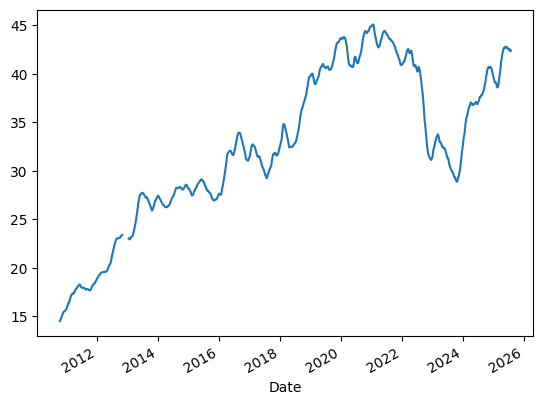

In [7]:
ma_window = 50
moving_average = vz_us.rolling(window=ma_window).mean()
moving_average.plot()
    

Date
2010-10-08    1.1410
2010-10-11    1.1794
2010-10-12    0.9270
2010-10-13    0.7474
2010-10-14    0.8242
               ...  
2025-07-23    0.5148
2025-07-24    0.7396
2025-07-25    0.7174
2025-07-28   -0.0162
2025-07-29    0.3354
Name: VZ UN, Length: 3674, dtype: float64


<Axes: xlabel='Date'>

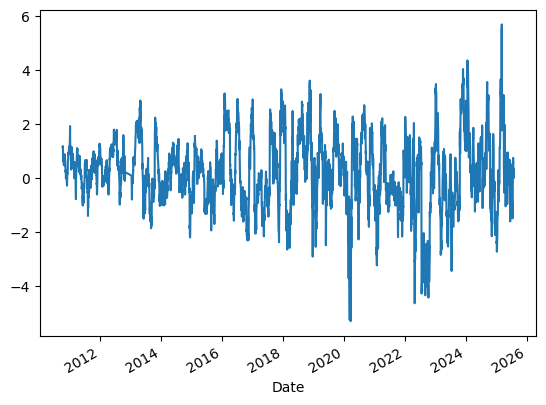

In [8]:
# calculate how the data deviate from the mean
deviation = vz_us - moving_average
deviation = deviation.dropna() #remove NA because moving average has missing values
print(deviation)
deviation.plot()



In [9]:
the_mean = 0
above_mean = deviation > 0


In [14]:
crossing = (above_mean != above_mean.shift(1)) & (above_mean.shift(1).notna())
crossing_dates = vz_us[crossing].index
print(crossing_dates)

IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

NameError: name 'crossing_dates' is not defined

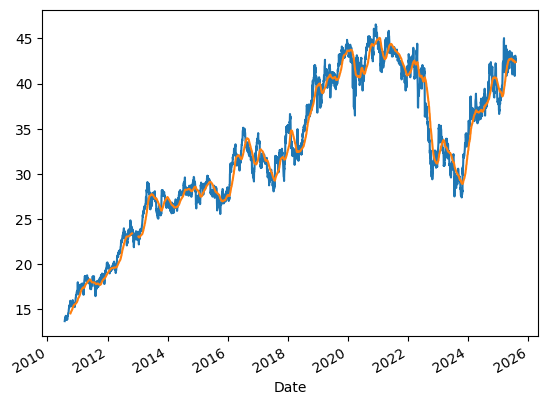

In [13]:

vz_us.plot(label="VZ UN")
moving_average.plot(label="Moving Average")

# Mark crossing dates
plt.scatter(crossing_dates, vz_us[crossing_dates], color='red', label='Crossings', zorder=3)

plt.legend()
plt.title("VZ UN with Moving Average and Crossing Dates")
plt.show()

In [ ]:
time_between_crossings = pd.Series(crossing_dates).diff().dt.days.dropna()
print(time_between_crossings.unique())


NameError: name 'time_between_crossings' is not defined

In [ ]:
#average crossing time - extension will be a more robust model with more explanatory variables and deternmining where you are in the mean reverse cycle
average_crossing_time = time_between_crossings.mean()
print(average_crossing_time)

median_crossing_time = time_between_crossings.median()
print(median_crossing_time)

17.789473684210527
7.0


<Axes: xlabel='Date'>

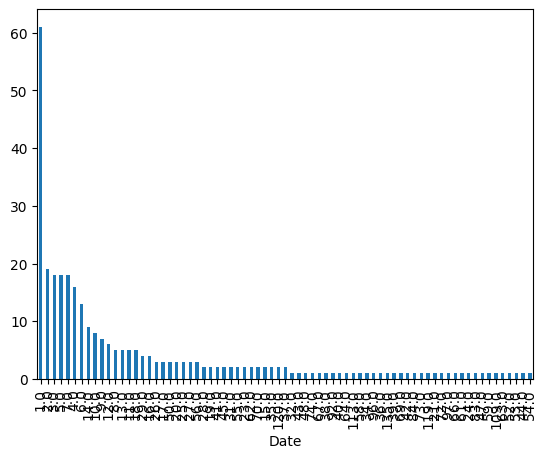

In [80]:
time_between_crossings_count = time_between_crossings.value_counts()
time_between_crossings_count.plot.bar()